# 03 · When will they churn? Survival analysis

The classifier in notebook 02 answers *whether* a customer churns. Survival analysis
answers *when*. It also handles something classification ignores: for 73% of
customers the outcome has not happened **yet**.

**Framing**

* Time axis: `tenure` in months. Event: `Churn = 1`. Active customers are
  **right-censored** at their current tenure: we only know they have stayed at least that
  long.
* Same 80/20 train/test split as notebook 02. The 11 customers with `tenure = 0` carry no
  follow-up time and are dropped (11 of 7,043).
* **Covariates exclude tenure and everything derived from it.** `TotalCharges` ≈ `tenure`
  × `MonthlyCharges`, so including it would leak the outcome. The classifier may use
  tenure (it is known at prediction time), but here tenure *is* the outcome.

**Models** (fit by `make train`; see `src/churn/survival.py`)

| Model | Why |
|---|---|
| Kaplan-Meier (no covariates) | Baseline: one population curve for everyone |
| Cox proportional hazards | Interpretable hazard ratios; assumes effects are constant over time |
| Cox PH stratified by contract | Separate baseline hazard per contract type, the remedy for its PH violation |
| Random survival forest | Non-parametric: no PH assumption, captures interactions |

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr

from churn import plots, survival
from churn.config import CONFIG, latest_model_dir
from churn.data import load_clean_data, split_train_test
from churn.evaluate import brier_over_time

plots.apply_style()
pd.set_option("display.precision", 3)

run_dir = latest_model_dir()
metrics = json.loads((run_dir / "metrics.json").read_text())
surv_metrics = metrics["survival"]
models = joblib.load(run_dir / "survival_models.joblib")

df = load_clean_data()
train_df, test_df = split_train_test(df, CONFIG.split.test_size, CONFIG.seed)
s_train, s_test = survival.survival_frame(train_df), survival.survival_frame(test_df)
d_train, e_train = survival.survival_arrays(s_train)
d_test, e_test = survival.survival_arrays(s_test)
print(
    f"Run {metrics['run']['version']} · survival train {len(s_train):,} customers "
    f"({e_train.mean():.1%} events) · test {len(s_test):,} ({e_test.mean():.1%} events)"
)

Run 20261028T085142Z-6387247 · survival train 5,626 customers (26.6% events) · test 1,406 (26.6% events)


## 1. Cox proportional hazards: what accelerates churn?

A hazard ratio (HR) multiplies the instantaneous churn rate. HR = 0.5 means churning at
half the rate of the reference customer at every tenure. Categorical covariates are
compared with a reference level (month-to-month contract, DSL internet, electronic-check
payment, "No" for services). The numeric covariates (`MonthlyCharges`, number of add-on
services) are standardised, so their HR is per standard deviation. A small L2 penalty
(0.01) stabilises the estimates.

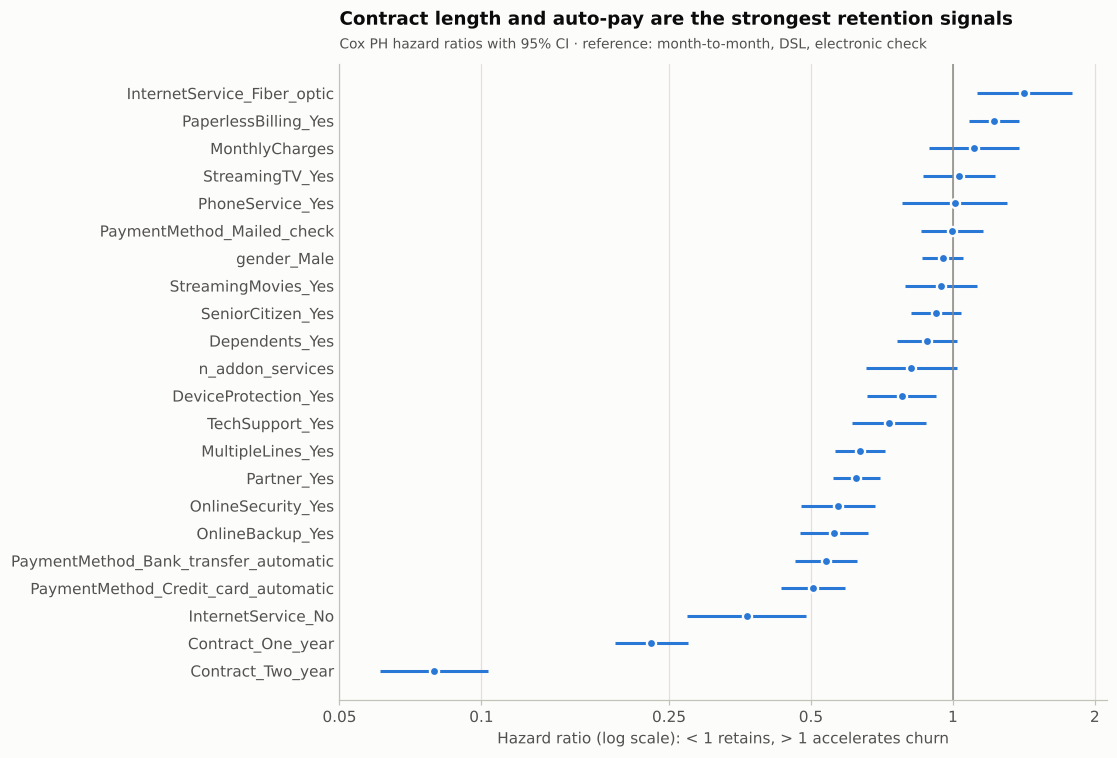

In [2]:
cox = models["Cox PH"]
fig, ax = plt.subplots(figsize=(9, 7.5))
plots.plot_hazard_ratios(cox.summary, ax=ax)
plots.set_title(
    ax,
    "Contract length and auto-pay are the strongest retention signals",
    "Cox PH hazard ratios with 95% CI · reference: month-to-month, DSL, electronic check",
)
plots.save_figure(fig, "cox_hazard_ratios")
plt.show()

In [3]:
hr = cox.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.columns = ["HR", "CI low", "CI high", "p"]
hr.sort_values("HR")

,HR,CI low,CI high,p
covariate,,,,
Contract_Two_year,0.079,0.061,0.103,1.846e-79
Contract_One_year,0.229,0.192,0.274,7.955e-59
InternetService_No,0.366,0.273,0.489,1.234e-11
PaymentMethod_Credit_card_automatic,0.505,0.432,0.591,1.741e-17
PaymentMethod_Bank_transfer_automatic,0.538,0.463,0.627,1.255e-15
OnlineBackup_Yes,0.560,0.474,0.660,6.179e-12
OnlineSecurity_Yes,0.571,0.476,0.685,1.497e-09
Partner_Yes,0.624,0.556,0.701,1.725e-15
MultipleLines_Yes,0.635,0.563,0.716,1.362e-13


* **Contract dominates.** One-year customers churn at about 0.23× and two-year
  customers at about 0.08× the hazard of month-to-month customers. That is a 4× and 12×
  difference in churn speed.
* **Automatic payment** (card or bank transfer) roughly halves the hazard relative to
  electronic checks.
* **Product depth retains.** Customers with online backup, online security, multiple
  lines, tech support or device protection churn more slowly. Customers without
  internet service churn slowest of all (HR 0.37).
* **Fiber optic (HR 1.42) and paperless billing (HR 1.23) accelerate churn**, consistent
  with the SHAP drivers in notebook 02.
* `MonthlyCharges` is not significant *given* the services. A bill is almost a
  deterministic sum of the services subscribed, so the price effect is absorbed by the
  service dummies. Gender, senior status and dependents have no significant effect.

## 2. Is the proportional-hazards assumption reasonable?

Cox assumes each covariate multiplies the hazard by the *same* factor at every tenure.
Two checks:

1. **Visual:** log(−log S(t)) against log(t) per contract group should give roughly
   parallel curves.
2. **Formal:** the Schoenfeld-residual test (lifelines `proportional_hazard_test`, rank
   time transform) per covariate.

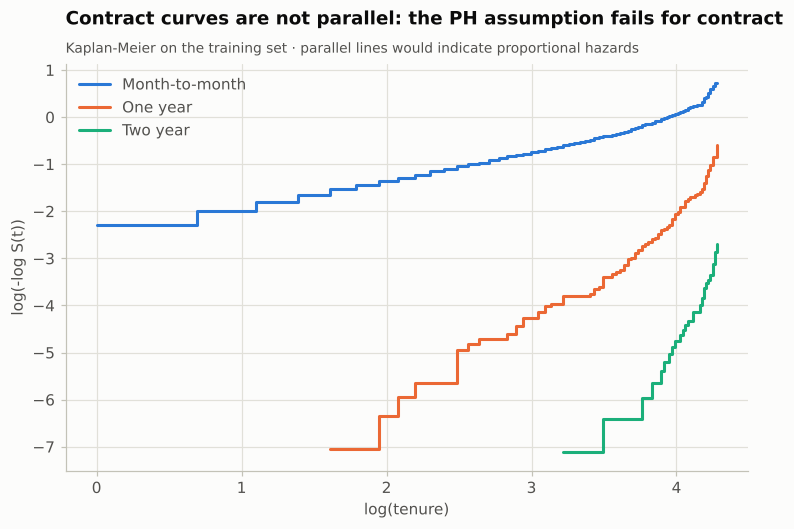

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
plots.plot_log_minus_log(s_train, "Contract", ["Month-to-month", "One year", "Two year"], ax=ax)
plots.set_title(
    ax,
    "Contract curves are not parallel: the PH assumption fails for contract",
    "Kaplan-Meier on the training set · parallel lines would indicate proportional hazards",
)
plots.save_figure(fig, "ph_check_contract")
plt.show()

In [5]:
alpha = 0.05
ph_unstrat = cox.proportional_hazards_test()
ph_strat = models["Cox PH (stratified by contract)"].proportional_hazards_test()
print(
    f"Unstratified Cox: {(ph_unstrat['p'] < alpha).sum()} of {len(ph_unstrat)} covariates violate PH at p < {alpha}"
)
print(
    f"Stratified by contract: {(ph_strat['p'] < alpha).sum()} of {len(ph_strat)} covariates violate PH at p < {alpha}"
)
pd.concat(
    {
        "unstratified": ph_unstrat[["test_statistic", "p"]].head(6),
        "stratified by contract": ph_strat[["test_statistic", "p"]].head(6),
    },
    axis=1,
)

Unstratified Cox: 6 of 22 covariates violate PH at p < 0.05
Stratified by contract: 5 of 20 covariates violate PH at p < 0.05


unstratified             \
                                      test_statistic          p   
Contract_One_year                             17.883  2.349e-05   
PaymentMethod_Credit_card_automatic           13.030  3.065e-04   
MultipleLines_Yes                             11.817  5.870e-04   
Partner_Yes                                    4.257  3.909e-02   
TechSupport_Yes                                4.028  4.475e-02   
PaymentMethod_Bank_transfer_automatic          3.982  4.600e-02   
StreamingMovies_Yes                              NaN        NaN   

                                      stratified by contract             
                                              test_statistic          p  
Contract_One_year                                        NaN        NaN  
PaymentMethod_Credit_card_automatic                   12.317  4.489e-04  
MultipleLines_Yes                                      9.484  2.073e-03  
Partner_Yes                                            4.389  3.617e-02  
TechSupport_Yes                                        4.107  4.270e-02  
PaymentMethod_Bank_transfer_automatic                  3.926  4.756e-02  
StreamingMovies_Yes                                    2.970  8.481e-02

* Visually and formally, **contract type is the clearest violation**. The one-year and
  month-to-month curves converge over time instead of staying parallel. A single hazard
  ratio averages a contract effect that is enormous early on (during the contract term)
  and weaker later.
* **Remedy: stratify on contract.** Each contract type gets its own baseline hazard, so
  no proportionality is assumed for it. Contract no longer has a coefficient, which costs
  us its hazard ratio. Section 1's unstratified estimates remain a useful *average*
  summary.
* Five weaker violations remain after stratification: auto-pay by credit card / bank
  transfer, multiple lines, partner and tech support. With 5,600 customers the test can
  detect small departures, and none of these covariates is a top driver. Time-varying
  coefficients (e.g. covariate × log t interactions) are a possible refinement. The
  random survival forest below makes no PH assumption at all and serves as a robustness
  check.

## 3. Model comparison on the held-out test set

* **Concordance index (Harrell's C):** across comparable pairs of customers, how often
  does the model predict the earlier churner as riskier? 0.5 = random, 1 = perfect. The
  risk score is minus the restricted mean survival time, which is valid for stratified
  Cox and forests as well.
* **Integrated Brier score (IBS):** squared error of the predicted survival probability
  averaged over months 1-71, with inverse-probability-of-censoring weights estimated on
  the training set. It measures calibration *and* discrimination. Lower is better, and
  the Kaplan-Meier curve is the no-covariate reference.

In [6]:
comparison = pd.DataFrame(surv_metrics["models"]).T.rename(
    columns={"c_index": "C-index ↑", "integrated_brier_score": "Integrated Brier ↓"}
)
comparison["IBS improvement vs Kaplan-Meier"] = (
    1
    - comparison["Integrated Brier ↓"]
    / comparison.loc["Kaplan-Meier (no covariates)", "Integrated Brier ↓"]
).map("{:.0%}".format)
print(f"Primary model (lowest IBS): {surv_metrics['primary_model']}")
comparison

Primary model (lowest IBS): Cox PH (stratified by contract)


,C-index ↑,Integrated Brier ↓,IBS improvement vs Kaplan-Meier
Kaplan-Meier (no covariates),0.500,0.183,0%
Cox PH,0.855,0.084,54%
Cox PH (stratified by contract),0.855,0.083,55%
Random survival forest,0.845,0.091,50%


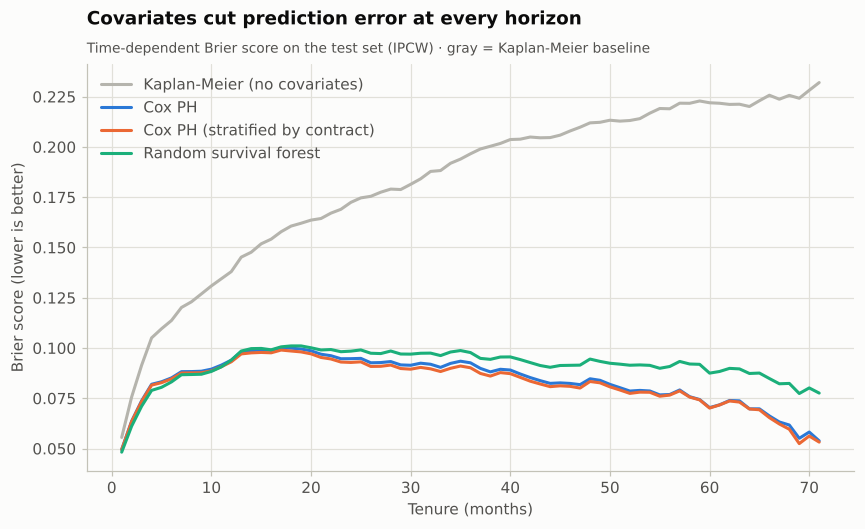

In [7]:
times = survival.IBS_TIMES
scores = {
    name: brier_over_time(
        d_train, e_train, d_test, e_test, model.predict_survival(s_test)[:, times], times
    )
    for name, model in models.items()
}
fig, ax = plt.subplots(figsize=(9, 4.8))
plots.plot_brier_over_time(times, scores, baseline="Kaplan-Meier (no covariates)", ax=ax)
plots.set_title(
    ax,
    "Covariates cut prediction error at every horizon",
    "Time-dependent Brier score on the test set (IPCW) · gray = Kaplan-Meier baseline",
)
plots.save_figure(fig, "survival_brier_over_time")
plt.show()

* All covariate models are far better than the population curve. The stratified Cox
  model has the lowest integrated Brier score (**0.083 vs 0.183** for Kaplan-Meier, a
  55% reduction) and the best concordance (**0.855**). It is the primary survival model.
* Stratification improves on the plain Cox model only slightly (0.084 → 0.083 IBS). Its
  main benefit is a *valid* model rather than a more accurate one.
* The random survival forest is close behind (C = 0.845). It was not tuned (fixed,
  a-priori hyperparameters, to avoid test-set snooping). As with LightGBM vs logistic
  regression in notebook 02, the signal here is mostly additive and a well-specified
  linear model is hard to beat.
* For the covariate models, error peaks around months 15-20, when month-to-month
  customers churn most and outcomes are least predictable, and then declines. The
  Kaplan-Meier baseline keeps deteriorating because one curve cannot separate
  long-lived contract customers from early churners. The forest falls behind the Cox
  models mainly at longer horizons.

## 4. Per-customer predictions: survival curves and expected remaining tenure

For an *active* customer with current tenure t₀, the relevant curve is the **conditional**
survival S(t | T > t₀) = S(t) / S(t₀). Three summaries come from it:

* **P(churn in the next 12 months)** = 1 − S(t₀ + 12) / S(t₀).
* **Expected active months over the next 12 months** = E[min(T − t₀, 12) | T > t₀]. The
  window is the same for everyone, so this is comparable across customers. Multiplied
  by `MonthlyCharges` it gives the expected revenue over the next year.
* **Expected remaining tenure** = E[min(T, 72) − t₀ | T > t₀]. It is *restricted to the
  72-month observation window*, because the curves cannot be extrapolated beyond the
  longest observed tenure. The window shrinks as t₀ grows, so long-tenure customers get
  small values by construction. Compare customers with the 12-month measure instead.

The 12-month measures need t₀ + 12 ≤ 72, so customers past month 60 are left blank
rather than extrapolated.

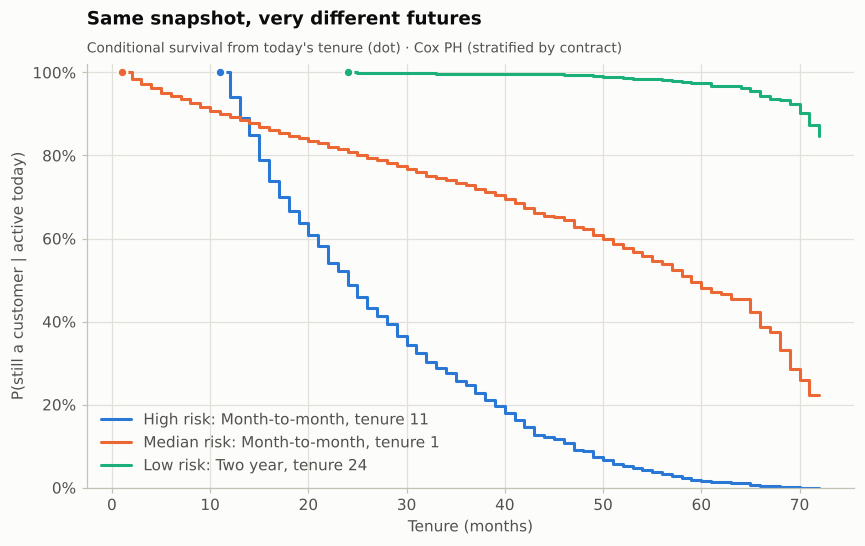

In [8]:
primary = models[surv_metrics["primary_model"]]
pred = pd.read_csv(run_dir / "test_predictions.csv")
active = pred[(pred["Churn"] == 0) & (pred["tenure"] > 0)].copy()

# Three active customers at the 95th, 50th and 5th percentile of 12-month churn risk.
ranked = active.dropna(subset=["p_churn_12m_survival"]).sort_values("p_churn_12m_survival")
picks = {
    "High risk": ranked.iloc[int(0.95 * (len(ranked) - 1))],
    "Median risk": ranked.iloc[int(0.50 * (len(ranked) - 1))],
    "Low risk": ranked.iloc[int(0.05 * (len(ranked) - 1))],
}
rows = test_df.set_index("customerID").loc[[r["customerID"] for r in picks.values()]].reset_index()
surv = primary.predict_survival(rows)
cond = survival.conditional_survival(surv, rows["tenure"])

labels = [f"{k}: {r['Contract']}, tenure {r['tenure']}" for k, r in picks.items()]
fig, ax = plt.subplots(figsize=(9, 5))
plots.plot_customer_survival(
    survival.TIME_GRID,
    dict(zip(labels, cond, strict=True)),
    dict(zip(labels, rows["tenure"].astype(int), strict=True)),
    ax=ax,
)
plots.set_title(
    ax,
    "Same snapshot, very different futures",
    f"Conditional survival from today's tenure (dot) · {surv_metrics['primary_model']}",
)
plots.save_figure(fig, "customer_survival_curves")
plt.show()

In [9]:
cols = {
    "Contract": "contract",
    "tenure": "tenure (mo)",
    "MonthlyCharges": "monthly $",
    "p_churn_12m_survival": "P(churn ≤ 12 mo)",
    "expected_months_next_12m": "expected active months, next 12",
    "expected_remaining_tenure": "expected remaining tenure (≤ 72)",
    "p_churn": "classifier P(churn)",
}
pd.DataFrame(picks).T[["customerID", *cols]].rename(columns=cols)

,customerID,contract,tenure (mo),monthly $,P(churn ≤ 12 mo),"expected active months, next 12",expected remaining tenure (≤ 72),classifier P(churn)
High risk,2501-XWWTZ,Month-to-month,11,70.2,0.478,8.946,16.396,0.449
Median risk,1194-SPVSP,Month-to-month,1,19.65,0.115,11.293,49.378,0.291
Low risk,9548-LERKT,Two year,24,19.75,0.003,11.98,47.053,0.018


### Across the active test customers

In [10]:
active["expected revenue next 12m"] = active["MonthlyCharges"] * active["expected_months_next_12m"]
active["revenue lost to churn next 12m"] = (
    active["MonthlyCharges"] * 12 - active["expected revenue next 12m"]
)
by_contract = active.groupby("Contract")[
    [
        "p_churn_12m_survival",
        "expected_months_next_12m",
        "expected_remaining_tenure",
        "revenue lost to churn next 12m",
    ]
].median()
by_contract.columns = [
    "median P(churn ≤ 12 mo)",
    "median active months, next 12",
    "median remaining tenure (≤ 72)",
    "median revenue lost, next 12 mo ($)",
]
by_contract

,median P(churn ≤ 12 mo),"median active months, next 12",median remaining tenure (≤ 72),"median revenue lost, next 12 mo ($)"
Contract,,,,
Month-to-month,0.201,10.833,27.774,67.321
One year,0.040,11.815,25.998,9.710
Two year,0.010,11.957,7.855,1.616


In [11]:
valid = active["p_churn_12m_survival"].notna()
rho = spearmanr(active.loc[valid, "p_churn"], active.loc[valid, "p_churn_12m_survival"]).statistic
print(
    f"Expected 12-month revenue lost to churn (survival model), {valid.sum():,} active customers "
    f"with tenure ≤ 60: ${active.loc[valid, 'revenue lost to churn next 12m'].sum():,.0f}\n"
    f"Spearman rank correlation, classifier P(churn) vs survival P(churn ≤ 12 mo): {rho:.2f}"
)

Expected 12-month revenue lost to churn (survival model), 772 active customers with tenure ≤ 60: $44,912
Spearman rank correlation, classifier P(churn) vs survival P(churn ≤ 12 mo): 0.77


* The median month-to-month customer has roughly a 1-in-5 chance of churning in the
  next year, against ~4% for one-year and ~1% for two-year customers.
* The "remaining tenure (≤ 72)" column shows why the restricted measure must be read
  carefully. Two-year customers *look* short-lived only because most are already near
  month 72. On the common 12-month horizon they are the most stable group.
* The classifier and the survival model **rank customers consistently** (Spearman ≈
  0.77) without being redundant. The classifier scores the snapshot label. The survival
  model gives a horizon-explicit probability and the expected *timing* of revenue loss,
  which the retention campaign can use for prioritisation (who first) and for budgeting
  (how much revenue is at stake per month).

## 5. Limitations

* **Snapshot data.** Covariates are measured at the snapshot, not at sign-up. A customer
  may have switched contract or added services along the way (time-varying covariates
  are not available), so hazard ratios are associations with the *current* profile.
* **How churn is recorded.** The dataset documentation describes `Churn` as "left within
  the last month". Read literally, customers who left earlier are missing (left
  truncation), which would bias absolute survival levels downwards in the analysis above.
  Like most analyses of this semi-synthetic dataset, we treat it as a standard
  right-censored cohort. Rankings (C-index) are less sensitive to this than absolute
  probabilities.
* **Remaining PH violations** in the stratified Cox model are small but not zero (section 2).
* **72-month horizon.** No customer is observed beyond 6 years, so lifetime value beyond
  that needs a parametric extrapolation (e.g. Weibull), deliberately out of scope here.

## 6. Summary

| | Kaplan-Meier | Cox PH | Cox PH, stratified by contract | Random survival forest |
|---|---|---|---|---|
| C-index (test) | 0.500 | 0.855 | **0.855** | 0.845 |
| Integrated Brier (test) | 0.183 | 0.084 | **0.083** | 0.091 |

The stratified Cox model is the primary time-to-churn model. It is interpretable,
satisfies the main PH requirement and is the best on both metrics. It turns each active
customer into a conditional survival curve, a 12-month churn probability and an
expected number of active months. Those feed directly into revenue-at-risk planning.